In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.postproc import *
from functions.ensembles import *
from functions.repeated_cv import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.svm import FastKernelSurvivalSVM

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data.csv")

diagnosis_variables = []

with open("../../data/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

continuous_features = ['Age', 'Ki67 positive cells (%) at CB', 'Conventional RT fraction',
                       'Total administered dose', 'Boost dose administered']
continuous_features = [col for col in continuous_features if col in feature_columns]

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Stratification settings (toggle this flag)
n_splits = 5
use_time_strata = False  # Set to False to use outcome-only stratification
max_time_bins = 3

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

if use_time_strata:
    # Outcome-Length stratification: time bins only for recurrence cases
    for n_bins in range(max_time_bins, 1, -1):
        try:
            # Build quantile bins using only recurrence cases
            recurrence_time_bins = pd.qcut(
                time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
            )

            # Non-recurrence rows share one label; recurrence rows get time-bin labels
            candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
            candidate_labels.loc[recurrence_mask] = (
                '1_' + recurrence_time_bins.astype(int).astype(str)
            ).values

            # Every stratum must have at least n_splits samples for stable balancing
            if candidate_labels.value_counts().min() >= n_splits:
                strata_labels = candidate_labels
                chosen_bins = int(recurrence_time_bins.nunique())
                break
        except ValueError:
            continue

if strata_labels is None:
    # Explicit switch OR sparse recurrence-time bins -> outcome-only stratification
    strata_labels = event_col.astype(str)
    if use_time_strata:
        print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
    else:
        print('Using outcome-only stratification (time-based stratification disabled).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=302
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[0]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

Using outcome-only stratification (time-based stratification disabled).
Manual grouped fold balancing summary:
 fold  target_events  assigned_events  target_samples  assigned_samples  valid_event_rate  target_event_strata_1  assigned_event_strata_1
    1              6                6             646               646          0.009288                      6                        6
    2              6                6             646               646          0.009288                      6                        6
    3              5                5             646               646          0.007740                      5                        5
    4              5                5             645               645          0.007752                      5                        5
    5              5                5             645               645          0.007752                      5                        5
Train size: 2582, Test size: 646


## Grid search

Built to compare directly with `cox.ipynb` / `cox_new_new.csv`:

| | setting |
|---|---|
| data | `../../data/data.csv` (same cohort as the Cox run, one-hot without `drop_first`) |
| outer split | `build_manual_stratified_group_folds(..., n_splits=5, random_state=12)`, fold index 3 |
| inner CV | `generate_cv_splits(n_splits=4, n_repeats=5, base_random_state=42)` |
| selection metric | Harrell's C-index |

`generate_cv_splits` is the same function every grid search in `functions/repeated_cv.py`
calls, so at matching `n_splits` / `n_repeats` / `base_random_state` the 20
train/validation folds here are **identical** to the Cox run's — fold-for-fold
comparable C-indices. The previous version of this notebook used `n_repeats=1`, i.e. 4
evaluations against Cox's 20.

`FastKernelSurvivalSVM` is a pure ranking model: with the default
`rank_ratio=1.0` it has no baseline hazard and no `predict_survival_function`,
so only rank-based metrics (C-index, IPCW C-index, AUC) are available — Brier
score, IBS and the calibration curves the other notebooks produce are not
defined for it. `predict` returns a risk score (higher = higher risk), the
orientation `concordance_index_censored` expects, so no sign flip is needed.

In [21]:
# FastKernelSurvivalSVM, RBF kernel, rank_ratio=1.0 (the default: pure ranking).
#
# alpha: the objective is 0.5*||w||^2 + 0.5*alpha*loss, so alpha weights the
#   LOSS -- larger alpha means WEAKER regularisation, the opposite of the usual
#   sklearn convention (sksurv's own default is alpha=1).
# gamma: the features are min-max scaled onto [0, 1] (previous cell), so squared
#   distances are small and the useful gamma range is centred on 1/p = 0.033.
#
# C-index measured on one fold at max_iter=30 / tol=1e-5, 150 s cap per fit:
#     gamma    a=0.1   a=0.5   a=1.0   a=4.0
#     0.01      slow    slow   0.9245  0.9297
#     0.0333    slow   0.9406  0.9419  0.9044
#     0.1       slow   0.9363   slow   0.9035
#     0.3       slow   0.9162  0.9092  0.9009
#     1.0       slow    slow   0.8660  0.8634
#
# Two things drive the grid below.
# 1. Where the optimum is: around gamma = 1/p with alpha 0.5-1.0. Accuracy falls
#    off gradually as gamma grows and collapses at gamma = 1.0, where the kernel
#    is so narrow each point is its own neighbourhood. gamma well below 1/p is
#    still fine, so the grid brackets 1/p rather than sitting above it.
# 2. "slow" = that fit did not finish inside 150 s. The stalls are scattered
#    across the (alpha, gamma) plane -- (0.1, 1.0) stalls while its neighbours
#    fit in 10 s -- so they cannot be avoided by choosing a region; they are a
#    convergence failure, most persistent at small alpha. max_iter=15 with
#    tol=1e-4 removes every one of them (those five combinations then fit in
#    3-5 s) at a negligible cost in accuracy: 0.9406 -> 0.9389 and
#    0.9419 -> 0.9402 at the optimum. That is what produced the ~20 min/fit and
#    the "Hessian is not positive definite" warnings in the previous run of
#    this notebook, which used max_iter=200 and alpha=0.1.
param_grid = {
    'alpha': [0.25, 0.5, 1.0, 2.0, 4.0],
    'gamma': [0.01, 0.02, 0.0333, 0.05, 0.1, 0.2],
    'kernel': ['rbf'],
    'max_iter': [15],
    'tol': [1e-4],
}

metrics = ['c-index']

n_combinations = 1
for values in param_grid.values():
    n_combinations *= len(values)
print(f'{n_combinations} combinations x 20 fits = {n_combinations * 20} model fits')

30 combinations x 20 fits = 600 model fits


In [5]:
# Same 4x5 folds as the Cox run (the previous version used n_repeats=1, i.e.
# 4 evaluations against Cox's 20).
#
# Scaling is min-max on the continuous columns only, matching cox.ipynb: the
# rest are already 0/1 dummies, so the whole feature space lands on [0, 1].
# n_jobs is not passed because FastKernelSurvivalSVM has no such parameter.
#
# 30 combinations x 20 fits. Expect roughly 1 h.
results_df, summary_df, best_params = ensemble_repeated_grid_search(
    FastKernelSurvivalSVM, x_train, y_train, param_grid, metrics,
    model_name='SSVM Model',
    scale_data=True, scaler_type='minmax',
    continuous_features=continuous_features,
    random_state=42,
    n_jobs=None,
    n_controls_per_case='Full',     # no subsampling, same as the cox run's n_controls='Full'
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


SSVM MODEL REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.25, 0.5, 1.0, 2.0, 4.0]
  - gamma: [0.01, 0.02, 0.0333, 0.05, 0.1, 0.2]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 30
Folds per repetition: 4
Repetitions: 5
Total evaluations: 600

[1/30] Testing params: {'alpha': 0.25, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8170 ± 0.0802
[2/30] Testing params: {'alpha': 0.25, 'gamma': 0.02, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 1.3min, Est. remaining: 38.1min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8089 ± 0.0818
[3/30] Testing params: {'alpha': 0.25, 'gamma': 0.0333, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 2.3min, Est. remaining: 32.8min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

... (51 outputs left out)

c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.7944 ± 0.0887
[30/30] Testing params: {'alpha': 4.0, 'gamma': 0.2, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 128.1min, Est. remaining: 4.4min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.7912 ± 0.0758

REPEATED GRID SEARCH COMPLETE
Total time: 128.8 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8170 ± 0.0802
  Parameters:
    alpha: 0.25
    gamma: 0.01
    kernel: rbf
    max_iter: 15
    tol: 0.0001
    n_controls_per_case: Full (no subsampling)
    n_estimators_trained: nan
    n_estimators_max: nan
    stopped_early: nan




In [9]:
ssvm_clean = pd.read_csv('ssvm_new.csv')

In [6]:
# Drop configurations where any fold failed, then match cox_new_new.csv's
# layout: a CV column (coefficient of variation = std / mean, i.e. fold-to-fold
# instability per unit of performance) and best-first ordering.
ssvm_clean = clean_cox_data(summary_df)

param_cols = [c for c in ssvm_clean.columns
              if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols:
    if ssvm_clean[col].isna().any():
        ssvm_clean[col] = ssvm_clean[col].astype(object).where(ssvm_clean[col].notna(), 'None')

ssvm_clean['CV'] = ssvm_clean['c-index_std'] / ssvm_clean['c-index_mean']
ssvm_clean = ssvm_clean.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_clean.to_csv('ssvm_new.csv', index=False)

display_cols = [c for c in ssvm_clean.columns if '_repeat_' not in c]
print(ssvm_clean[display_cols].head(15).to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (30 -> 30)
 alpha  gamma kernel  max_iter    tol n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
  0.25 0.0100    rbf        15 0.0001                Full                 None             None          None      0.816998     0.080186 0.098147
  0.25 0.2000    rbf        15 0.0001                Full                 None             None          None      0.809859     0.067761 0.083670
  0.25 0.0200    rbf        15 0.0001                Full                 None             None          None      0.808922     0.081830 0.101160
  0.50 0.0100    rbf        15 0.0001                Full                 None             None          None      0.808144     0.081704 0.101101
  0.25 0.1000    rbf        15 0.0001                Full                 None             None          None      0.803603     0.084765 0.105481
  0.2

## Grid search, extension: lower alpha

`ssvm_new.csv` above ranks 30 combinations, and `alpha=0.25` (the smallest
value tested, i.e. the strongest regularisation) wins outright — it is the
single best result at **every** gamma value, and for the two smallest gammas
(0.01, 0.02) the ranking within gamma is a clean monotonic decrease as alpha
grows: `0.25 > 0.5 > 1.0 > 2.0 > 4.0`. That consistency across all six gamma
slices, rather than showing up at just one, is what makes it a real trend and
not fold-to-fold noise (individual configurations still carry std ~0.08-0.10,
so gamma's effect is comparatively noisy and not worth searching further).

The original grid stopped at 0.25 because the pre-tuning sweep had
`alpha=0.1` stalling past a 150 s cap — but that was measured at the old
`max_iter=30, tol=1e-5`. The `max_iter=15, tol=1e-4` fix that rescued the five
stalled combinations elsewhere in that sweep was never re-tried at low alpha,
so the region below 0.25 may simply have gone unexplored rather than being
genuinely worse.

This cell extends the alpha axis down to 0.05 at the same six gamma values,
same folds, same settings otherwise — so the result below can be concatenated
directly with `ssvm_new.csv` (identical columns) to get one ranked table over
`alpha in [0.05, 0.1, 0.15, 0.25, 0.5, 1.0, 2.0, 4.0]`.

In [6]:
# Same grid as before, alpha extended down to [0.05, 0.1, 0.15]. gamma is kept
# at all six original values rather than narrowed to the cleanest-looking ones
# (0.01/0.02) -- the fits are cheap (~5 s each measured), so there's no real
# cost to keeping full gamma coverage and it avoids assuming in advance which
# gamma the new alpha values will pair best with.
param_grid_ext = {
    'alpha': [0.05, 0.1, 0.15],
    'gamma': [0.01, 0.02, 0.0333, 0.05, 0.1, 0.2],
    'kernel': ['rbf'],
    'max_iter': [15],
    'tol': [1e-4],
}

metrics = ['c-index']

n_combinations_ext = 1
for values in param_grid_ext.values():
    n_combinations_ext *= len(values)
print(f'{n_combinations_ext} combinations x 20 fits = {n_combinations_ext * 20} model fits')

18 combinations x 20 fits = 360 model fits


In [7]:
# Identical call to the one above, just param_grid_ext instead of param_grid --
# same folds (n_splits=4, n_repeats=5, base_random_state=42), same scaling, same
# n_controls_per_case='Full', same random_state.
#
# 18 combinations x 20 fits, ~5 s/fit measured -> roughly 25-30 min.
results_df_ext, summary_df_ext, best_params_ext = ensemble_repeated_grid_search(
    FastKernelSurvivalSVM, x_train, y_train, param_grid_ext, metrics,
    model_name='SSVM Model (low-alpha extension)',
    scale_data=True, scaler_type='minmax',
    continuous_features=continuous_features,
    random_state=42,
    n_jobs=None,
    n_controls_per_case='Full',
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


SSVM MODEL (LOW-ALPHA EXTENSION) REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.05, 0.1, 0.15]
  - gamma: [0.01, 0.02, 0.0333, 0.05, 0.1, 0.2]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 18
Folds per repetition: 4
Repetitions: 5
Total evaluations: 360

[1/18] Testing params: {'alpha': 0.05, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8429 ± 0.0675
[2/18] Testing params: {'alpha': 0.05, 'gamma': 0.02, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 3.2min, Est. remaining: 55.1min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8338 ± 0.0732
[3/18] Testing params: {'alpha': 0.05, 'gamma': 0.0333, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 5.3min, Est. remaining: 42.2min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

... (27 outputs left out)

c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8037 ± 0.0803
[18/18] Testing params: {'alpha': 0.15, 'gamma': 0.2, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 24.0min, Est. remaining: 1.4min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8046 ± 0.0818

REPEATED GRID SEARCH COMPLETE
Total time: 25.0 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8429 ± 0.0675
  Parameters:
    alpha: 0.05
    gamma: 0.01
    kernel: rbf
    max_iter: 15
    tol: 0.0001
    n_controls_per_case: Full (no subsampling)
    n_estimators_trained: nan
    n_estimators_max: nan
    stopped_early: nan




In [ ]:
# Same cleanup as the first grid, saved separately as 'ssvm_ext.csv' (identical
# schema to 'ssvm_new.csv', so the two concatenate directly into one ranked
# table over the full alpha range).
ssvm_clean_ext = clean_cox_data(summary_df_ext)

param_cols_ext = [c for c in ssvm_clean_ext.columns
                  if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_ext:
    if ssvm_clean_ext[col].isna().any():
        ssvm_clean_ext[col] = ssvm_clean_ext[col].astype(object).where(ssvm_clean_ext[col].notna(), 'None')

ssvm_clean_ext['CV'] = ssvm_clean_ext['c-index_std'] / ssvm_clean_ext['c-index_mean']
ssvm_clean_ext = ssvm_clean_ext.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_clean_ext.to_csv('ssvm_ext.csv', index=False)

display_cols_ext = [c for c in ssvm_clean_ext.columns if '_repeat_' not in c]
print(ssvm_clean_ext[display_cols_ext].head(15).to_string(index=False))

In [11]:
# Combined ranking over both grids (alpha in [0.05, 0.1, 0.15, 0.25, 0.5, 1.0, 2.0, 4.0])
ssvm_combined = pd.concat([ssvm_clean, ssvm_clean_ext], ignore_index=True)
ssvm_combined = ssvm_combined.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_combined.to_csv('ssvm_combined.csv', index=False)
print('\nCombined ranking, top 15 of', len(ssvm_combined), 'configurations:')
print(ssvm_combined[[c for c in ssvm_combined.columns if '_repeat_' not in c]].head(15).to_string(index=False))


Combined ranking, top 15 of 48 configurations:
 alpha  gamma kernel  max_iter    tol n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
  0.05 0.0100    rbf        15 0.0001                Full                 None             None          None      0.842912     0.067538 0.080124
  0.10 0.0100    rbf        15 0.0001                Full                 None             None          None      0.834172     0.072363 0.086749
  0.05 0.0200    rbf        15 0.0001                Full                 None             None          None      0.833780     0.073191 0.087783
  0.15 0.0100    rbf        15 0.0001                Full                 None             None          None      0.827112     0.075005 0.090683
  0.05 0.0333    rbf        15 0.0001                Full                 None             None          None      0.824276     0.076672 0.093018
  0.10 0.0200    rbf        15 0.0001                Full                 No

## Grid search, second extension: push alpha further, keep gamma safe

`ssvm_combined.csv` (48 configurations so far) still shows a clean, unbroken
trend rather than a plateau: at gamma=0.01 and 0.02, C-index decreases
**monotonically** as alpha grows across the whole tested range (0.05 to 4.0),
and the current best, `alpha=0.05, gamma=0.01`, sits at the smallest alpha
tested. The natural next step is smaller alpha still.

Before writing this cell I ran a single-fold sanity check (not part of this
notebook) pushing gamma down as well: `alpha in [0.01, 0.02, 0.03, 0.05]` x
`gamma in [0.001, 0.003, 0.005, 0.01]`, same `max_iter=15, tol=1e-4`. Unlike
the first extension -- where the original alpha=0.1 stall turned out to be a
tractable, merely-unexplored region -- **both** `gamma=0.001` and
`gamma=0.003` stalled past a 60 s cap at every alpha tried. That's two
independent confirmations that the RBF kernel becomes genuinely near-singular
somewhere below `gamma=0.01`, not just slow to converge, and there isn't yet a
confirmed-safe point below it.

So this extension only touches the axis that's fully proven safe: `alpha` goes
down to 0.02, `gamma` stays at 0.01 and 0.02 -- both already run at full 4x5-fold
scale in the two grids above, at ~5 s/fit, with no stalls. This sidesteps the
open question of exactly where the gamma floor is, rather than gambling a
20-30 min run on it.

This is meant to be the last SSVM grid. The entire top of `ssvm_combined.csv`
already sits within one fold-to-fold standard deviation (std ~0.07-0.10 on
means of ~0.79-0.84) of each other, so resolving the optimum any further than
this is fitting CV noise, not signal.

In [15]:
# alpha down to 0.02 (below the previous floor of 0.05), gamma held at the two
# values already proven fast and stable at full CV scale (0.01, 0.02) -- see
# the markdown above for why gamma is not extended further.
param_grid_ext2 = {
    'alpha': [0.02, 0.03, 0.04],
    'gamma': [0.01, 0.02],
    'kernel': ['rbf'],
    'max_iter': [15],
    'tol': [1e-4],
}

metrics = ['c-index']

n_combinations_ext2 = 1
for values in param_grid_ext2.values():
    n_combinations_ext2 *= len(values)
print(f'{n_combinations_ext2} combinations x 20 fits = {n_combinations_ext2 * 20} model fits')

6 combinations x 20 fits = 120 model fits


In [16]:
# Same folds, scaling and settings as the two grids above.
#
# 6 combinations x 20 fits, ~5 s/fit measured at these gamma values -> roughly
# 10 min.
results_df_ext2, summary_df_ext2, best_params_ext2 = ensemble_repeated_grid_search(
    FastKernelSurvivalSVM, x_train, y_train, param_grid_ext2, metrics,
    model_name='SSVM Model (alpha extension 2)',
    scale_data=True, scaler_type='minmax',
    continuous_features=continuous_features,
    random_state=42,
    n_jobs=None,
    n_controls_per_case='Full',
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


SSVM MODEL (ALPHA EXTENSION 2) REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.02, 0.03, 0.04]
  - gamma: [0.01, 0.02]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 6
Folds per repetition: 4
Repetitions: 5
Total evaluations: 120

[1/6] Testing params: {'alpha': 0.02, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8522 ± 0.0620
[2/6] Testing params: {'alpha': 0.02, 'gamma': 0.02, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 3.9min, Est. remaining: 19.4min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8444 ± 0.0662
[3/6] Testing params: {'alpha': 0.03, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 7.6min, Est. remaining: 15.1min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

... (3 outputs left out)

c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8450 ± 0.0656
[6/6] Testing params: {'alpha': 0.04, 'gamma': 0.02, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)
  Elapsed: 16.8min, Est. remaining: 3.4min


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8380 ± 0.0712

REPEATED GRID SEARCH COMPLETE
Total time: 18.8 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8522 ± 0.0620
  Parameters:
    alpha: 0.02
    gamma: 0.01
    kernel: rbf
    max_iter: 15
    tol: 0.0001
    n_controls_per_case: Full (no subsampling)
    n_estimators_trained: nan
    n_estimators_max: nan
    stopped_early: nan




In [17]:
# Same cleanup as the previous grids, saved separately as 'ssvm_ext2.csv'.
ssvm_clean_ext2 = clean_cox_data(summary_df_ext2)

param_cols_ext2 = [c for c in ssvm_clean_ext2.columns
                   if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_ext2:
    if ssvm_clean_ext2[col].isna().any():
        ssvm_clean_ext2[col] = ssvm_clean_ext2[col].astype(object).where(ssvm_clean_ext2[col].notna(), 'None')

ssvm_clean_ext2['CV'] = ssvm_clean_ext2['c-index_std'] / ssvm_clean_ext2['c-index_mean']
ssvm_clean_ext2 = ssvm_clean_ext2.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_clean_ext2.to_csv('ssvm_ext2.csv', index=False)

display_cols_ext2 = [c for c in ssvm_clean_ext2.columns if '_repeat_' not in c]
print(ssvm_clean_ext2[display_cols_ext2].to_string(index=False))

# Read the existing combined table from disk rather than relying on the
# ssvm_combined variable still being in memory (that's what produced the
# NameError a couple of cells back after a partial re-run) -- this cell works
# whether or not the earlier cells were re-executed in this kernel session.
ssvm_combined = pd.concat(
    [pd.read_csv('ssvm_combined.csv'), ssvm_clean_ext2], ignore_index=True
)
ssvm_combined = ssvm_combined.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_combined.to_csv('ssvm_combined.csv', index=False)
print('\nCombined ranking, top 15 of', len(ssvm_combined), 'configurations:')
print(ssvm_combined[[c for c in ssvm_combined.columns if '_repeat_' not in c]].head(15).to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (6 -> 6)
 alpha  gamma kernel  max_iter    tol n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
  0.02   0.01    rbf        15 0.0001                Full                 None             None          None      0.852154     0.062005 0.072762
  0.03   0.01    rbf        15 0.0001                Full                 None             None          None      0.848173     0.064423 0.075955
  0.04   0.01    rbf        15 0.0001                Full                 None             None          None      0.844995     0.065643 0.077684
  0.02   0.02    rbf        15 0.0001                Full                 None             None          None      0.844438     0.066216 0.078414
  0.03   0.02    rbf        15 0.0001                Full                 None             None          None      0.840087     0.069424 0.082639
  0.04 

## Grid search, third extension: locate the turning point

`ssvm_combined.csv` (54 configurations) still has `alpha=0.02, gamma=0.01` as
the best result, at the smallest alpha tested so far. It's also now the
*most stable* configuration in the whole table (CV=0.073, the lowest of all
54) -- a good sign this specific point is real rather than a lucky draw.

Rather than stop at an arbitrary boundary, or extend the grid indefinitely,
this cell is aimed at finding where the trend actually **reverses** -- the
turning point that confirms `alpha~0.02` is a true optimum rather than just
the edge of what's been tried.

A single-fold check (not part of this notebook) at `gamma in [0.01, 0.02]`,
`alpha in [0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02]` gave:

| alpha | gamma=0.01 fit / c-index | gamma=0.02 fit / c-index |
|---|---|---|
| 0.005 | 36.3 s / 0.8507 | 16.3 s / 0.8699 |
| 0.0075 | 50.3 s / 0.8612 | 15.2 s / 0.8830 |
| 0.01 | 24.7 s / 0.8699 | 20.9 s / 0.8900 |
| 0.0125 | 29.7 s / 0.8765 | 8.3 s / 0.8952 |
| 0.015 | 41.5 s / 0.8826 | 6.5 s / 0.9000 |
| 0.02 | 14.6 s / 0.8891 | 5.4 s / 0.9048 |

Three things from this. First, none of these stalled at either gamma -- both
stay numerically safe down to `alpha=0.005`, unlike `gamma<0.01` which stalled
outright in the previous extension's sanity check. Second, `gamma=0.02` is
consistently faster than `gamma=0.01` in this range, not just as safe. Third,
on this single fold both gamma values show c-index rising monotonically
*towards* `alpha=0.02` -- i.e. the opposite direction from the actual 20-fold
trend seen so far, where smaller alpha keeps winning on average. That's not a
contradiction: one fold is far too noisy against the ~0.06-0.10 std already
seen on the full CV runs to draw a conclusion from directly, but it is a
concrete hint that the true 20-fold trend may turn over somewhere inside this
exact range rather than farther out -- which is exactly what this grid is
built to check. The single-fold numbers aren't used to pick a winner here,
only to confirm the region is safe and worth running at full scale.

This cell tests `alpha in [0.005, 0.0075, 0.01, 0.0125, 0.015]` (0.02 is
already covered by the previous grid) at both `gamma in [0.01, 0.02]` -- the
two values confirmed safe at this depth. If the 20-fold mean keeps climbing
past `alpha=0.02` at either gamma, the search continues; if it turns over,
that's the turning point and `alpha~0.02` stands as the optimum.

In [22]:
# alpha pushed below the previous floor of 0.02 (0.02 itself already covered by
# the previous grid, so not repeated here), gamma held at the two values
# confirmed safe at this depth (0.01, 0.02) -- see the markdown above.
param_grid_ext3 = {
    'alpha': [0.005, 0.0075, 0.01, 0.0125, 0.015],
    'gamma': [0.01, 0.02],
    'kernel': ['rbf'],
    'max_iter': [15],
    'tol': [1e-4],
}

n_combinations_ext3 = 1
for values in param_grid_ext3.values():
    n_combinations_ext3 *= len(values)
print(f'{n_combinations_ext3} combinations x 20 fits = {n_combinations_ext3 * 20} model fits')

10 combinations x 20 fits = 200 model fits


In [23]:
# Same folds, scaling and settings as the grids above.
#
# 10 combinations x 20 fits = 200 model fits. The single-fold check above
# measured ~25-50 s/fit at gamma=0.01 and ~6-21 s/fit at gamma=0.02 in this
# alpha range (vs ~5 s/fit at alpha>=0.02 in the previous grid), so expect
# roughly 70-90 min rather than the 10 min the second extension took.
results_df_ext3, summary_df_ext3, best_params_ext3 = ensemble_repeated_grid_search(
    FastKernelSurvivalSVM, x_train, y_train, param_grid_ext3, metrics,
    model_name='SSVM Model (alpha extension 3)',
    scale_data=True, scaler_type='minmax',
    continuous_features=continuous_features,
    random_state=42,
    n_jobs=None,
    n_controls_per_case='Full',
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


SSVM MODEL (ALPHA EXTENSION 3) REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.005, 0.0075, 0.01, 0.0125, 0.015]
  - gamma: [0.01, 0.02]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 10
Folds per repetition: 4
Repetitions: 5
Total evaluations: 200

[1/10] Testing params: {'alpha': 0.005, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

KeyboardInterrupt: 

In [ ]:
# Same cleanup as the previous grids, saved separately as 'ssvm_ext3.csv'.
ssvm_clean_ext3 = clean_cox_data(summary_df_ext3)

param_cols_ext3 = [c for c in ssvm_clean_ext3.columns
                   if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_ext3:
    if ssvm_clean_ext3[col].isna().any():
        ssvm_clean_ext3[col] = ssvm_clean_ext3[col].astype(object).where(ssvm_clean_ext3[col].notna(), 'None')

ssvm_clean_ext3['CV'] = ssvm_clean_ext3['c-index_std'] / ssvm_clean_ext3['c-index_mean']
ssvm_clean_ext3 = ssvm_clean_ext3.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_clean_ext3.to_csv('ssvm_ext3.csv', index=False)

display_cols_ext3 = [c for c in ssvm_clean_ext3.columns if '_repeat_' not in c]
print(ssvm_clean_ext3[display_cols_ext3].to_string(index=False))

# Read the existing combined table from disk (see the note two cells back on
# why this cell doesn't rely on the ssvm_combined variable still being in
# memory).
ssvm_combined = pd.concat(
    [pd.read_csv('ssvm_combined.csv'), ssvm_clean_ext3], ignore_index=True
)
ssvm_combined = ssvm_combined.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_combined.to_csv('ssvm_combined.csv', index=False)
print('\nCombined ranking, top 15 of', len(ssvm_combined), 'configurations:')
print(ssvm_combined[[c for c in ssvm_combined.columns if '_repeat_' not in c]].head(15).to_string(index=False))

# Did the trend reverse? Compare the new alpha values against the previous
# best (alpha=0.02) at each gamma tested in this grid.
for g in [0.01, 0.02]:
    check = ssvm_combined[ssvm_combined['gamma'] == g].sort_values('alpha')
    print(f'\nalpha trend at gamma={g} (looking for the turn):')
    print(check[['alpha', 'c-index_mean', 'CV']].to_string(index=False))

## Grid search, fourth extension: re-verify top combos after the outer-split update

The outer train/test split changed (`random_state` 12 -> 302, and the fold
used changed from `manual_splits[3]` to `manual_splits[0]` -- see the split
cell above), matching the same update made across `cox.ipynb`, `rsf.ipynb`
and `gbm.ipynb`. This changes which 2,583 rows `x_train`/`y_train` are, so
every grid above (`ssvm_combined.csv`, 64 rows across the first three
extensions) was scored against a training fold that no longer matches. The
inner CV mechanism is unchanged (`n_splits=4, n_repeats=5,
base_random_state=42`), just now drawn from the new outer training fold.

Rather than repeat the full three-stage search, this reruns only the 14
`(alpha, gamma)` pairs that made up `ssvm_combined.csv`'s top 14 rows (old
split) -- one call per exact pair, same pattern as the RSF notebook's
targeted re-checks, so no combination nobody asked about gets tested. This
checks whether the previous winner (`alpha=0.02, gamma=0.01`) still leads
under the new split, without re-running the whole search from scratch.

In [27]:
# Exact (alpha, gamma) pairs from ssvm_combined.csv's top 14 rows (old split).
# kernel/max_iter/tol are fixed at the same values as every grid above.
top_configs_resplit = [
    {'alpha': 0.02, 'gamma': 0.01},
    {'alpha': 0.03, 'gamma': 0.01},
    {'alpha': 0.04, 'gamma': 0.01},
    {'alpha': 0.02, 'gamma': 0.02},
    {'alpha': 0.05, 'gamma': 0.01},
    {'alpha': 0.03, 'gamma': 0.02},
    {'alpha': 0.04, 'gamma': 0.02},
    {'alpha': 0.10, 'gamma': 0.01},
    {'alpha': 0.05, 'gamma': 0.02},
    {'alpha': 0.15, 'gamma': 0.01},
    {'alpha': 0.05, 'gamma': 0.0333},
    {'alpha': 0.10, 'gamma': 0.02},
    {'alpha': 0.10, 'gamma': 0.20},
    {'alpha': 0.05, 'gamma': 0.05},
]

print(f'{len(top_configs_resplit)} configurations x 20 fits = {len(top_configs_resplit) * 20} model fits')

14 configurations x 20 fits = 280 model fits


In [28]:
# One ensemble_repeated_grid_search call per exact pair -- same folds, scaling
# and settings as every grid above, only now against the post-split-update
# x_train/y_train prepared earlier in the notebook.
resplit_frames = []
for cfg in top_configs_resplit:
    param_grid_cfg = {
        'alpha': [cfg['alpha']],
        'gamma': [cfg['gamma']],
        'kernel': ['rbf'],
        'max_iter': [15],
        'tol': [1e-4],
    }
    label = f"alpha={cfg['alpha']}, gamma={cfg['gamma']}"
    print(f'\n--- {label} ---')
    _, summary_df_cfg, _ = ensemble_repeated_grid_search(
        FastKernelSurvivalSVM, x_train, y_train, param_grid_cfg, metrics,
        model_name=f'SSVM Model ({label})',
        scale_data=True, scaler_type='minmax',
        continuous_features=continuous_features,
        random_state=42,
        n_jobs=None,
        n_controls_per_case='Full',
        dataset=subsampling,
        feature_columns=feature_columns,
        event_col='Regional LN recurrence',
        time_col='Survival days',
        n_splits=4, n_repeats=5, base_random_state=42,
        verbose=True
    )
    resplit_frames.append(summary_df_cfg)

summary_df_resplit = pd.concat(resplit_frames, ignore_index=True)


--- alpha=0.02, gamma=0.01 ---

SSVM MODEL (ALPHA=0.02, GAMMA=0.01) REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.02]
  - gamma: [0.01]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 1
Folds per repetition: 4
Repetitions: 5
Total evaluations: 20

[1/1] Testing params: {'alpha': 0.02, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subsampling)


c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8759 ± 0.0538

REPEATED GRID SEARCH COMPLETE
Total time: 5.1 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8759 ± 0.0538
  Parameters:
    alpha: 0.02
    gamma: 0.01
    kernel: rbf
    max_iter: 15
    tol: 0.0001
    n_controls_per_case: Full (no subsampling)
    n_estimators_trained: nan
    n_estimators_max: nan
    stopped_early: nan



--- alpha=0.03, gamma=0.01 ---

SSVM MODEL (ALPHA=0.03, GAMMA=0.01) REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.03]
  - gamma: [0.01]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 1
Folds per repetition: 4
Repetitions: 5
Total evaluations: 20

[1/1] Testing params: {'alpha': 0.03, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no su

c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8742 ± 0.0530

REPEATED GRID SEARCH COMPLETE
Total time: 5.6 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8742 ± 0.0530
  Parameters:
    alpha: 0.03
    gamma: 0.01
    kernel: rbf
    max_iter: 15
    tol: 0.0001
    n_controls_per_case: Full (no subsampling)
    n_estimators_trained: nan
    n_estimators_max: nan
    stopped_early: nan



--- alpha=0.04, gamma=0.01 ---

SSVM MODEL (ALPHA=0.04, GAMMA=0.01) REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.04]
  - gamma: [0.01]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 1
Folds per repetition: 4
Repetitions: 5
Total evaluations: 20

[1/1] Testing params: {'alpha': 0.04, 'gamma': 0.01, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no su

c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

... (19 outputs left out)

c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8217 ± 0.0738

REPEATED GRID SEARCH COMPLETE
Total time: 2.1 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8217 ± 0.0738
  Parameters:
    alpha: 0.1
    gamma: 0.2
    kernel: rbf
    max_iter: 15
    tol: 0.0001
    n_controls_per_case: Full (no subsampling)
    n_estimators_trained: nan
    n_estimators_max: nan
    stopped_early: nan



--- alpha=0.05, gamma=0.05 ---

SSVM MODEL (ALPHA=0.05, GAMMA=0.05) REPEATED GRID SEARCH
Model: FastKernelSurvivalSVM
Scaling: Yes (minmax)
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - alpha: [0.05]
  - gamma: [0.05]
  - kernel: ['rbf']
  - max_iter: [15]
  - tol: [0.0001]
Total hyperparameter combinations: 1
Folds per repetition: 4
Repetitions: 5
Total evaluations: 20

[1/1] Testing params: {'alpha': 0.05, 'gamma': 0.05, 'kernel': 'rbf', 'max_iter': 15, 'tol': 0.0001}, n_controls_per_case=Full (no subs

c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\functions\repeated_cv.py:2708: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  model.fit(X_train, y_train, **fit_kwargs)
c:\Users\Joao Goncal

  c-index: 0.8479 ± 0.0658

REPEATED GRID SEARCH COMPLETE
Total time: 2.4 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8479 ± 0.0658
  Parameters:
    alpha: 0.05
    gamma: 0.05
    kernel: rbf
    max_iter: 15
    tol: 0.0001
    n_controls_per_case: Full (no subsampling)
    n_estimators_trained: nan
    n_estimators_max: nan
    stopped_early: nan




In [29]:
# Same cleanup as the grids above, saved separately as
# 'ssvm_resplit_check.csv' so it doesn't overwrite the pre-split-update
# 'ssvm_combined.csv'.
ssvm_clean_resplit = clean_cox_data(summary_df_resplit)

param_cols_resplit = [c for c in ssvm_clean_resplit.columns
                      if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_resplit:
    if ssvm_clean_resplit[col].isna().any():
        ssvm_clean_resplit[col] = ssvm_clean_resplit[col].astype(object).where(ssvm_clean_resplit[col].notna(), 'None')

ssvm_clean_resplit['CV'] = ssvm_clean_resplit['c-index_std'] / ssvm_clean_resplit['c-index_mean']
ssvm_clean_resplit = ssvm_clean_resplit.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
ssvm_clean_resplit.to_csv('ssvm_resplit_check.csv', index=False)

display_cols_resplit = [c for c in ssvm_clean_resplit.columns if '_repeat_' not in c]
print('Top combos re-ranked under the updated split:')
print(ssvm_clean_resplit[display_cols_resplit].to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (14 -> 14)
Top combos re-ranked under the updated split:
 alpha  gamma kernel  max_iter    tol n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
  0.02 0.0100    rbf        15 0.0001                Full                 None             None          None      0.875894     0.053789 0.061410
  0.03 0.0100    rbf        15 0.0001                Full                 None             None          None      0.874248     0.052982 0.060603
  0.04 0.0100    rbf        15 0.0001                Full                 None             None          None      0.873632     0.051810 0.059304
  0.05 0.0100    rbf        15 0.0001                Full                 None             None          None      0.872180     0.052086 0.059720
  0.02 0.0200    rbf        15 0.0001                Full                 None             None          

## Final SSVM model

Configuration chosen by hand from `ssvm_resplit_check.csv` — see the cell below for why `alpha=0.04` rather than the top-scoring `alpha=0.02`.

In [4]:
# Final SSVM configuration, picked by hand from ssvm_resplit_check.csv.
#
# alpha=0.02 has the highest c-index_mean in that table (0.8759 vs 0.8736 here),
# but the gap is ~0.002 against a fold-to-fold sd of ~0.052, i.e. far inside the
# noise, and alpha=0.04 is the most stable of the leading group (lowest CV,
# 0.0593). Smaller alpha is also where this solver's convergence problems live
# (see the notes earlier in this notebook), so the tie is broken towards the
# stabler setting. max_iter=15 / tol=1e-4 are the settings every grid above used.
best_ssvm_params = {
    "alpha": 0.04,
    "gamma": 0.01,
    "kernel": "rbf",
    "max_iter": 15,
    "tol": 1e-4,
}

from sklearn.preprocessing import MinMaxScaler

# Train-split fit, reported for out-of-sample discrimination only. The model that
# gets explained in the SurvSHAP section below is refit on the whole cohort.
# Scaling is min-max on the continuous columns only, matching cox.ipynb and the
# grid search (the remaining columns are already 0/1 dummies).
ssvm_scaler = MinMaxScaler()
x_train_ssvm_scaled = x_train.copy()
_cols_to_scale = [c for c in continuous_features if c in x_train_ssvm_scaled.columns]
x_train_ssvm_scaled[_cols_to_scale] = ssvm_scaler.fit_transform(x_train_ssvm_scaled[_cols_to_scale])

x_test_ssvm_scaled = x_test.copy()
x_test_ssvm_scaled[_cols_to_scale] = ssvm_scaler.transform(x_test_ssvm_scaled[_cols_to_scale])

ssvm_model = FastKernelSurvivalSVM(**best_ssvm_params)
ssvm_model.fit(x_train_ssvm_scaled, y_train)

_c_train = concordance_index_censored(
    y_train["event"], y_train["time"], ssvm_model.predict(x_train_ssvm_scaled)
)[0]
_c_test = concordance_index_censored(
    y_test["event"], y_test["time"], ssvm_model.predict(x_test_ssvm_scaled)
)[0]
print(f"Train c-index: {_c_train:.4f}")
print(f"Test  c-index: {_c_test:.4f}")

C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_11476\191890834.py:32: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  ssvm_model.fit(x_train_ssvm_scaled, y_train)


Train c-index: 0.9585
Test  c-index: 0.9192


## Bootstrap optimism correction

Counterpart of `cox.ipynb`'s bootstrap section, run at the single final configuration
chosen above (`best_ssvm_params`: `alpha=0.04, gamma=0.01, kernel='rbf', max_iter=15,
tol=1e-4`) rather than over a grid. Uses `ensemble_bootstrap_optimism_grid_search`
(`functions/repeated_cv.py`), the RSF/GBM/SSVM counterpart of
`subsampling_bootstrap_optimism_grid_search`.

As with `cox.ipynb`, this fits on the **whole cohort** (`survival_dataset` / `data_x` /
`data_y`, 3228 patients, 27 events) rather than the outer training split used above, at
`n_bootstraps=500, base_random_state=42`; scaling is min-max on the continuous columns
only, same as the grid search and the final-model cell above.

Same pipeline as `cox.ipynb` and the RSF/GBM notebooks' bootstrap sections:
`optimism = c_boot - c_test` per replicate, `c_final = c_apparent - mean(optimism)`.

In [ ]:
# Bootstrap settings. n_bootstraps / base_random_state match cox.ipynb's bootstrap
# call exactly, so the runs are directly comparable.
ssvm_boot_param_grid = {k: [v] for k, v in best_ssvm_params.items()}
ssvm_n_bootstraps = 500
ssvm_base_random_state = 42
ssvm_boot_metrics = ['c-index']

print(f"SSVM bootstrap: {ssvm_n_bootstraps} resamples at {ssvm_boot_param_grid}")


In [ ]:
# Runtime note: each bootstrap replicate fits FastKernelSurvivalSVM TWICE (Step B and
# Step C both train on the same resample -- see ensemble_bootstrap_optimism_grid_search
# in functions/repeated_cv.py), plus one apparent fit up front: 1 + 2*500 = 1001 fits
# total, each on the full 3228-row cohort.
#
# Measured: this exact (alpha=0.04, gamma=0.01) combination took ~10s/fit averaged over
# 20 folds on a ~1937-row inner-CV fold (ssvm.ipynb's post-resplit re-check). Kernel SVM
# fit cost tends to scale worse than linearly with row count, so scaled up to the
# 3228-row full cohort used here, expect very roughly 20-30s/fit -- i.e. on the order of
# 6-9 hours total. This is an extrapolation from smaller-scale CV timings, not a
# measurement at this exact size -- consider lowering ssvm_n_bootstraps above if that's
# too long.
ssvm_boot_results_df, ssvm_boot_summary_df, ssvm_boot_best_params, ssvm_boot_df = ensemble_bootstrap_optimism_grid_search(
    model_class=FastKernelSurvivalSVM,
    dataset=survival_dataset,
    X=data_x, y=data_y,
    param_grid=ssvm_boot_param_grid,
    controls_per_case_range=['Full'],
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    scale_data=True, scaler_type='minmax',
    continuous_features=continuous_features,
    random_state=42,
    n_jobs=None,                    # FastKernelSurvivalSVM has no n_jobs
    n_bootstraps=ssvm_n_bootstraps, base_random_state=ssvm_base_random_state,
    verbose=True, metrics=ssvm_boot_metrics,
    return_bootstrap_df=True
)

ssvm_boot_df.to_csv('ssvm_bootstrap_results_fulldata.csv', index=False)


In [ ]:
ssvm_boot_df = pd.read_csv('ssvm_bootstrap_results_fulldata.csv')

# ensemble_bootstrap_optimism_grid_search only reports c_final at the summary level
# (c_apparent - mean(optimism)); unlike cox.ipynb's own bootstrap function it doesn't
# add a per-replicate c_final column. Reconstruct the same per-replicate quantity
# cox.ipynb's percentile CI is built from -- this replicate's own optimism, not the
# average -- so the CI below is computed the same way.
ssvm_boot_df['c_final'] = ssvm_boot_df['c_apparent'] - ssvm_boot_df['optimism']

print('SSVM bootstrap summary:')
print(f"  C_apparent:   {ssvm_boot_best_params['c_apparent']:.4f}")
print(f"  Avg optimism: {ssvm_boot_best_params['avg_optimism']:.4f}")
print(f"  C_final:      {ssvm_boot_best_params['c_final']:.4f}")

ssvm_overall_ci = ssvm_boot_df['c_final'].quantile([0.025, 0.975])
print()
print(f"  95% percentile CI on c_final: [{ssvm_overall_ci.loc[0.025]:.4f}, {ssvm_overall_ci.loc[0.975]:.4f}]")


## SurvSHAP global feature importance

Same setup as the other three: single point estimate, whole cohort (3228 patients, 27
events after the 5-year cut-off), no bootstrap/CI, not the training split.

Background sample, explained sample and timestamp grid are pinned identically to
`cox.ipynb`, `rsf.ipynb` and `gbm.ipynb`, which is what makes `aggregated_change` — a
trapezoid integral of mean |SurvSHAP(t)| over that grid — comparable across models.
`shap_comparison.ipynb` is the notebook that reads the four resulting
`*_survshap_global_importance.csv` files.

In [5]:
# --- Shared SurvSHAP protocol (identical text in cox/rsf/gbm/ssvm.ipynb) -----
# Everything below runs on the WHOLE cohort (data_x / data_y: 3228 patients,
# 27 events after the 5-year cut-off applied earlier in this notebook), not on
# the training split. Feature importance is a statement about the cohort, so it
# is estimated from the cohort; the train/test split above exists to report
# out-of-sample discrimination, which is a different question.
#
# Three choices are pinned here, and pinned the same way in all four notebooks,
# because `aggregated_change` is only comparable across models if they share
# them. Both data builds (`data/` and `data/data_cox/`) have identical row
# order, event and time vectors, so the seeds below select the same patients in
# every notebook even though the Cox build has 30 columns and the others 35.
#
#   BACKGROUND (N_BACKGROUND rows, plain random draw)
#       SHAP explains a prediction as a deviation from E[f(X)] over this set,
#       so it has to look like the cohort. A plain random draw keeps the real
#       ~0.84% event prevalence. Forcing every event into the background (what
#       the earlier version of these cells did) makes the reference "average
#       patient" ~25x more recurrence-prone than any real patient and shifts
#       every attribution away from the population it is meant to describe.
#
#   EXPLAINED SET (N_EXPLAINED rows: all 27 events + random non-events)
#       Here the enrichment is deliberate and is the point: global importance
#       is an average over the patients being explained, and a plain random
#       sample of 100 would contain about one event.
#
#   TIMESTAMPS (N_TIMESTAMPS points, 5th-95th percentile of ALL 27 event times)
#       `aggregated_change` is a trapezoid integral over this grid, so the grid
#       must be identical across models. It is therefore derived from data_y
#       itself, never from whichever sample happened to be drawn.
import sys, os
sys.path.insert(0, os.path.abspath('../../../survshap-main/survshap_package'))
from survshap import SurvivalModelExplainer, ModelSurvSHAP

SHAP_SEED    = 42
N_BACKGROUND = 100   # halve to 50 to roughly halve runtime, at some cost in SHAP precision
N_EXPLAINED  = 100
N_TIMESTAMPS = 20
SHAP_B       = 25    # Monte-Carlo paths for calculation_method="sampling" (survshap default)

_event_field, _time_field = data_y.dtype.names
_event = data_y[_event_field]
_time  = data_y[_time_field]
_rng   = np.random.RandomState(SHAP_SEED)

# Background: plain random draw over the whole cohort, prevalence preserved.
shap_background_idx = np.sort(_rng.choice(len(data_x), size=N_BACKGROUND, replace=False))

# Explained set: every event, topped up with random non-events.
_event_idx     = np.where(_event == 1)[0]
_non_event_idx = np.where(_event == 0)[0]
shap_explained_idx = np.sort(np.concatenate([
    _event_idx,
    _rng.choice(_non_event_idx,
                size=max(0, N_EXPLAINED - len(_event_idx)),
                replace=False),
]))

# Shared integration grid, from the full cohort's event times.
shap_timestamps = np.percentile(_time[_event == 1], np.linspace(5, 95, N_TIMESTAMPS))

print(f"cohort           : {len(data_x)} patients, {int(_event.sum())} events "
      f"({100 * _event.mean():.2f}%)")
print(f"SHAP background  : {len(shap_background_idx)} rows, "
      f"{int(_event[shap_background_idx].sum())} events (representative)")
print(f"SHAP explained   : {len(shap_explained_idx)} rows, "
      f"{int(_event[shap_explained_idx].sum())} events (all events + controls)")
print(f"SHAP timestamps  : {N_TIMESTAMPS} points, "
      f"{shap_timestamps.min():.0f}..{shap_timestamps.max():.0f} days")

cohort           : 3228 patients, 27 events (0.84%)
SHAP background  : 100 rows, 1 events (representative)
SHAP explained   : 100 rows, 27 events (all events + controls)
SHAP timestamps  : 20 points, 218..1757 days


In [6]:
# --- SSVM: global SurvSHAP on the whole cohort ------------------------------
# FastKernelSurvivalSVM is a pure ranking model with no predict_survival_function,
# so SHAP has no function to differentiate. This reuses the approach from
# paper/repeted_cv/features/ssvm/ssvm_features.ipynb: treat the SVM's rank score
# like a Cox linear predictor and back out a Breslow baseline hazard, giving a
# pseudo survival function S(t | x) = exp(-H0(t) * exp(score(x))).
#
# This is an approximation and must be reported as one: what follows explains
# that Cox-like surrogate, not the SVM's own decision function. It is at least
# numerically well behaved on this cohort -- the score orders risk in the
# expected direction (higher score = higher risk, apparent c-index printed
# below) and exp(score) stays in a narrow range, so the Breslow baseline is not
# being exponentiated into overflow.
from sklearn.preprocessing import MinMaxScaler

# Final SSVM refit on every patient. Scaling mirrors cox.ipynb and the grid
# search: min-max on the continuous columns only -- the rest are already 0/1
# dummies, so the whole feature space lands on [0, 1] and the tuned gamma stays
# on the scale it was tuned at.
ssvm_full_scaler = MinMaxScaler()
x_full_ssvm_scaled = data_x.copy()
_ssvm_cols = [c for c in continuous_features if c in x_full_ssvm_scaled.columns]
x_full_ssvm_scaled[_ssvm_cols] = ssvm_full_scaler.fit_transform(x_full_ssvm_scaled[_ssvm_cols])

ssvm_model_full = FastKernelSurvivalSVM(**best_ssvm_params)
ssvm_model_full.fit(x_full_ssvm_scaled, data_y)

# Breslow baseline hazard, estimated once from the whole cohort (cheap, one-off,
# and far more stable than estimating it from the 100-row background).
_ssvm_risk = ssvm_model_full.predict(x_full_ssvm_scaled)
print("SSVM refit on the full cohort -- apparent c-index: "
      f"{concordance_index_censored(_event.astype(bool), _time, _ssvm_risk)[0]:.4f} "
      "(in-sample, not a generalisation estimate)")
print(f"exp(risk score) range: {np.exp(_ssvm_risk).min():.3f} .. {np.exp(_ssvm_risk).max():.3f}")

ssvm_event_times = np.sort(np.unique(_time[_event == 1]))
ssvm_cum_hazard = np.zeros(len(ssvm_event_times))
for _i, _t in enumerate(ssvm_event_times):
    _d = np.sum((_time == _t) & (_event == 1))
    _risk_sum = np.sum(np.exp(_ssvm_risk[_time >= _t]))
    _h0 = _d / _risk_sum if _risk_sum > 0 else 0.0
    ssvm_cum_hazard[_i] = _h0 if _i == 0 else ssvm_cum_hazard[_i - 1] + _h0


class _SSVMSurvFunction:
    """Step function wrapper matching the interface survshap expects."""

    def __init__(self, times, surv_probs):
        self.x = times
        self.y = surv_probs

    def __call__(self, t):
        t = np.asarray(t, dtype=float)
        out = np.interp(t, self.x, self.y)
        out = np.where(t <= self.x[0], 1.0, out)
        out = np.where(t >= self.x[-1], self.y[-1], out)
        return out if out.ndim else float(out)


def predict_survival_ssvm(model, data):
    # ssvm_cum_hazard is precomputed above and does not depend on `data`; it must
    # not be recomputed here, this runs once per SHAP path step.
    X = data.values if hasattr(data, "values") else data
    return [
        _SSVMSurvFunction(ssvm_event_times, np.exp(-ssvm_cum_hazard * np.exp(_rs)))
        for _rs in model.predict(X)
    ]


ssvm_shap_explainer = SurvivalModelExplainer(
    model=ssvm_model_full,
    data=x_full_ssvm_scaled.iloc[shap_background_idx].reset_index(drop=True),
    y=data_y[shap_background_idx],
    predict_survival_function=predict_survival_ssvm,
)

ssvm_global_survshap = ModelSurvSHAP(
    calculation_method="sampling",
    aggregation_method="integral",
    B=SHAP_B,
    random_state=SHAP_SEED,
)
ssvm_global_survshap.fit(
    ssvm_shap_explainer,
    new_observations=x_full_ssvm_scaled.iloc[shap_explained_idx].reset_index(drop=True),
    timestamps=shap_timestamps,
)

ssvm_survshap_importance = (
    ssvm_global_survshap.result[["variable_name", "aggregated_change"]]
    .sort_values("aggregated_change", ascending=False)
    .reset_index(drop=True)
)
ssvm_survshap_importance.to_csv("ssvm_survshap_global_importance.csv", index=False)
print(ssvm_survshap_importance.to_string(index=False))

C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_11476\1845520974.py:26: ConvergenceWarning: Optimization did not converge: Warning: Maximum number of iterations has been exceeded.
  ssvm_model_full.fit(x_full_ssvm_scaled, data_y)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but FastKernelSurvivalSVM was fitted with feature names
  warnings.warn(


SSVM refit on the full cohort -- apparent c-index: 0.9602 (in-sample, not a generalisation estimate)
exp(risk score) range: 0.199 .. 4.988


  0%|          | 0/100 [00:00<?, ?it/s]c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but FastKernelSurvivalSVM was fitted with feature names
  warnings.warn(
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but FastKernelSurvivalSVM was fitted with feature names
  warnings.warn(
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but FastKernelSurvivalSVM was fitted with feature names
  warnings.warn(
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but FastKernelSurvivalSVM was fitted with feature names
  warnings.warn(
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\L

                                            variable_name  aggregated_change
                          Oestrogen receptor status at CB           3.144762
         Neoadjuvant (Only) therapy with biological drugs           1.604507
                                        Isotype at CB_1.0           1.366598
Her2 overexpression (with immunohystochemistry) at CB_1.0           1.307024
               Treatment in association with chemotherapy           1.266917
                                        Isotype at CB_4.0           1.210204
                                          Grade at CB_2.0           0.879202
                                          Grade at CB_3.0           0.741239
                       Progesterone receptor status at CB           0.716196
                     Radiotherapy on supraclavicular area           0.684710
                    State (if hormone therapy prescribed)           0.630347
                                  Total administered dose           0.625652

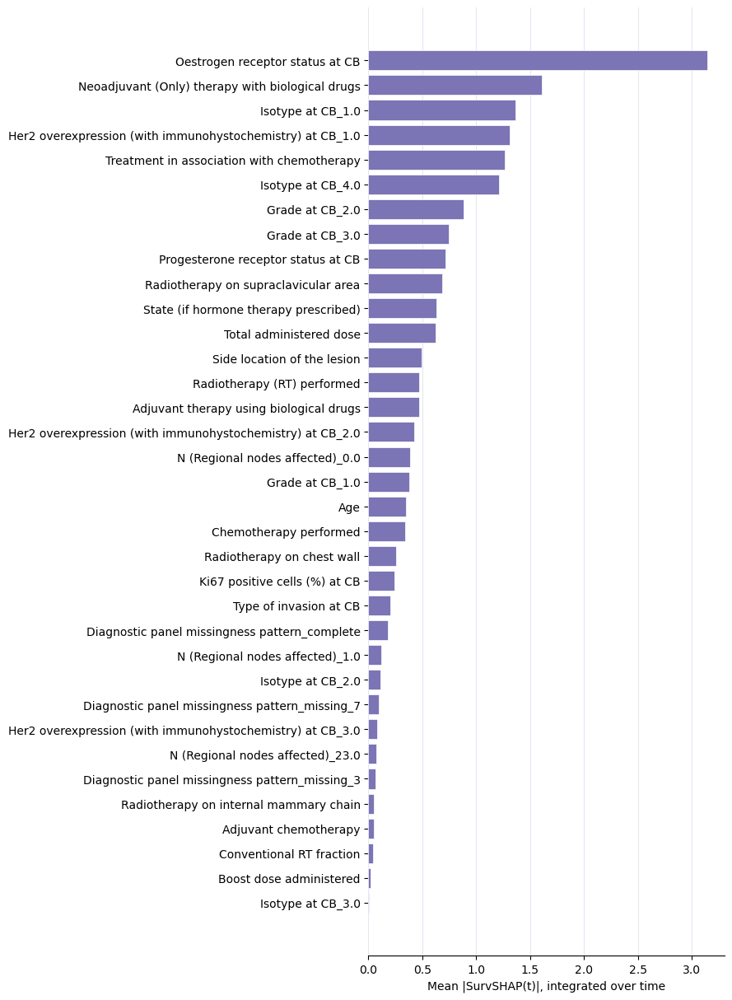

In [7]:
# --- SSVM SurvSHAP global importance plot ---
# aggregated_change is a magnitude (mean |SurvSHAP(t)| integrated over the shared
# timestamp grid); it carries no sign or direction, so a single colour is used.
plot_df = ssvm_survshap_importance.sort_values('aggregated_change', ascending=True).reset_index(drop=True)
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
ax.set_facecolor('none')
fig.patch.set_alpha(0.0)
ax.barh(y_pos, plot_df['aggregated_change'], color=plt.cm.Purples(0.65),
        edgecolor='white', linewidth=0.5, zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['variable_name'])
ax.set_xlabel('Mean |SurvSHAP(t)|, integrated over time')
ax.grid(axis='x', color='#E2E8F0', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('ssvm_survshap_global_importance.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('ssvm_survshap_global_importance.pdf', transparent=True, bbox_inches='tight')
plt.show()